In [ ]:

from google.colab import files

uploaded = files.upload()


Saving IMDb Movies India.csv to IMDb Movies India.csv


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

# Load the uploaded CSV
file_name = "IMDb Movies India.csv"
df = pd.read_csv(file_name, encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Dataset shape: (15509, 10)


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
0,,NaN,NaN,Drama,NaN,NaN,J.S. Randhawa,Manmauji,Birbal,Rajendra Bhatia
1,#Gadhvi (He thought he was Gandhi),(2019),109 min,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
2,#Homecoming,(2021),90 min,"Drama, Musical",NaN,NaN,Soumyajit Majumdar,Sayani Gupta,Plabita Borthakur,Roy Angana
3,#Yaaram,(2019),110 min,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
4,...And Once Again,(2010),105 min,Drama,NaN,NaN,Amol Palekar,Rajat Kapoor,Rituparna Sengupta,Antara Mali


In [ ]:

# Column names and data types
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nRating statistics:")
print(df["Rating"].describe())


Column names:
['Name', 'Year', 'Duration', 'Genre', 'Rating', 'Votes', 'Director', 'Actor 1', 'Actor 2', 'Actor 3']

Data types:
Name         object
Year         object
Duration     object
Genre        object
Rating      float64
Votes        object
Director     object
Actor 1      object
Actor 2      object
Actor 3      object
dtype: object

Missing values:
Name           0
Year         528
Duration    8269
Genre       1877
Rating      7590
Votes       7589
Director     525
Actor 1     1617
Actor 2     2384
Actor 3     3144
dtype: int64

Duplicate rows: 6

Rating statistics:
count    7919.000000
mean        5.841621
std         1.381777
min         1.100000
25%         4.900000
50%         6.000000
75%         6.800000
max        10.000000
Name: Rating, dtype: float64


In [ ]:

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove rows where the target rating is missing
df = df.dropna(subset=["Rating"]).copy()

# Convert rating to numeric
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df = df.dropna(subset=["Rating"]).copy()

# Clean numeric features
df["Year"] = pd.to_numeric(
    df["Year"].astype(str).str.extract(r"(\d{4})")[0],
    errors="coerce"
)

df["Duration"] = pd.to_numeric(
    df["Duration"].astype(str).str.extract(r"(\d+)")[0],
    errors="coerce"
)

df["Votes"] = pd.to_numeric(
    df["Votes"].astype(str).str.replace(",", "", regex=False),
    errors="coerce"
)

# Remove rows with impossible target ratings
df = df[df["Rating"].between(0, 10)].copy()

print("Shape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())
display(df.head())


Shape after cleaning: (7919, 10)

Missing values after cleaning:
Name           0
Year           0
Duration    2068
Genre        102
Rating         0
Votes          0
Director       5
Actor 1      125
Actor 2      200
Actor 3      292
dtype: int64


,Name,Year,Duration,Genre,Rating,Votes,Director,Actor 1,Actor 2,Actor 3
1,#Gadhvi (He thought he was Gandhi),2019,109.0,Drama,7.0,8,Gaurav Bakshi,Rasika Dugal,Vivek Ghamande,Arvind Jangid
3,#Yaaram,2019,110.0,"Comedy, Romance",4.4,35,Ovais Khan,Prateik,Ishita Raj,Siddhant Kapoor
5,...Aur Pyaar Ho Gaya,1997,147.0,"Comedy, Drama, Musical",4.7,827,Rahul Rawail,Bobby Deol,Aishwarya Rai Bachchan,Shammi Kapoor
6,...Yahaan,2005,142.0,"Drama, Romance, War",7.4,1086,Shoojit Sircar,Jimmy Sheirgill,Minissha Lamba,Yashpal Sharma
8,?: A Question Mark,2012,82.0,"Horror, Mystery, Thriller",5.6,326,Allyson Patel,Yash Dave,Muntazir Ahmad,Kiran Bhatia


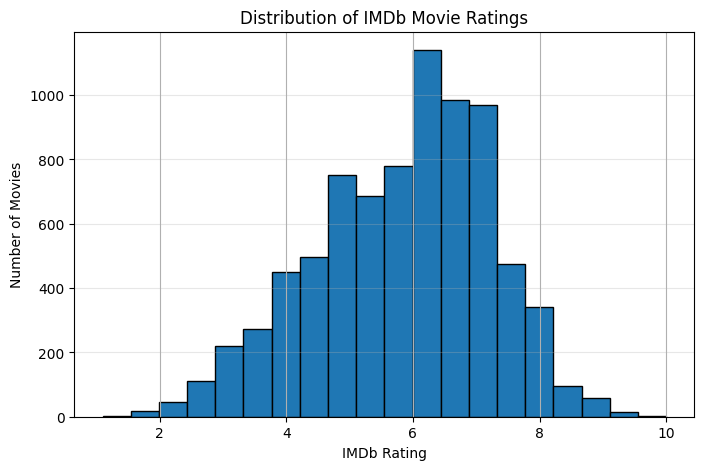

In [ ]:

plt.figure(figsize=(8, 5))
df["Rating"].hist(bins=20, edgecolor="black")
plt.title("Distribution of IMDb Movie Ratings")
plt.xlabel("IMDb Rating")
plt.ylabel("Number of Movies")
plt.grid(axis="y", alpha=0.3)
plt.show()


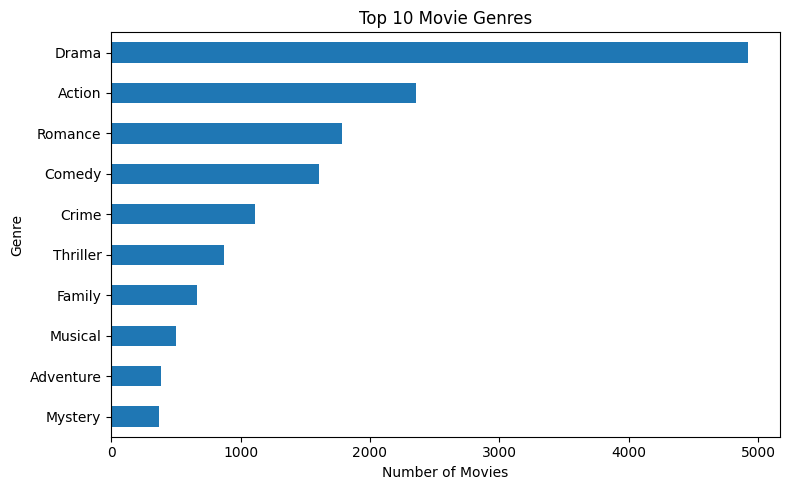

In [ ]:

genre_counts = (
    df["Genre"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
    .head(10)
)

genre_counts.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Top 10 Movie Genres")
plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


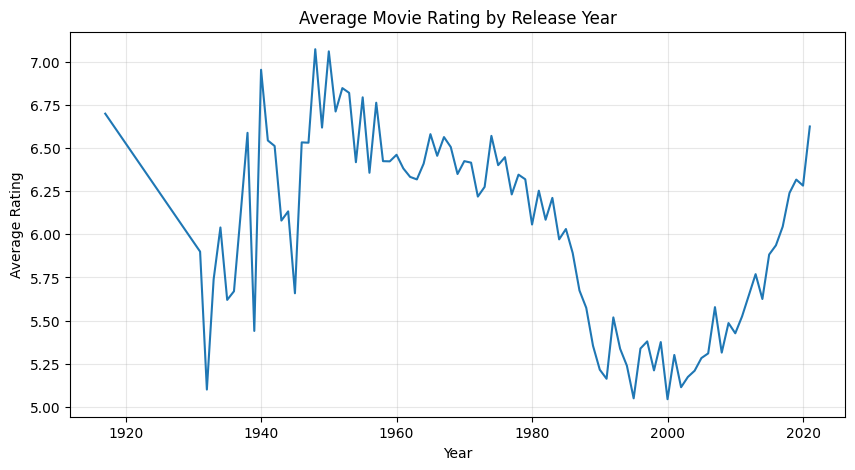

In [ ]:

yearly_rating = (
    df.dropna(subset=["Year"])
      .groupby("Year")["Rating"]
      .mean()
      .sort_index()
)

plt.figure(figsize=(10, 5))
plt.plot(yearly_rating.index, yearly_rating.values)
plt.title("Average Movie Rating by Release Year")
plt.xlabel("Year")
plt.ylabel("Average Rating")
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:

numeric_features = ["Year", "Duration", "Votes"]

categorical_features = [
    "Genre",
    "Director",
    "Actor 1",
    "Actor 2",
    "Actor 3"
]

feature_columns = numeric_features + categorical_features

X = df[feature_columns].copy()
y = df["Rating"].copy()

print("Number of input features:", len(feature_columns))
print("Number of samples:", len(X))
print("Target variable: Rating")


Number of input features: 8
Number of samples: 7919
Target variable: Rating


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


Training samples: 6335
Testing samples: 1584


In [ ]:

# Preprocessing for numeric features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Preprocessing for categorical features
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        min_frequency=10
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Create the model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1,
        max_features=0.8
    ))
])

# Train the model
model.fit(X_train, y_train)

print("Model training completed successfully!")


Model training completed successfully!


In [ ]:

# Predict ratings for the test set
y_pred = model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2): {r2:.4f}")


MODEL EVALUATION RESULTS
-----------------------------------
Mean Absolute Error (MAE): 0.8428
Root Mean Squared Error (RMSE): 1.1195
R-squared (R2): 0.3259


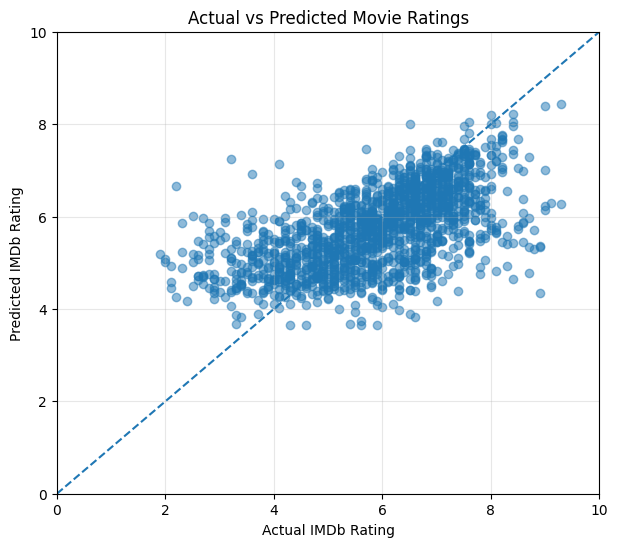

In [ ]:

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

# Ideal predictions lie on this line
plt.plot([0, 10], [0, 10], linestyle="--")

plt.xlabel("Actual IMDb Rating")
plt.ylabel("Predicted IMDb Rating")
plt.title("Actual vs Predicted Movie Ratings")
plt.xlim(0, 10)
plt.ylim(0, 10)
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:

# Compare predictions with actual ratings
results = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": y_pred
})

results["Absolute Error"] = (
    results["Actual Rating"] - results["Predicted Rating"]
).abs()

display(results.head(10).round(2))


,Actual Rating,Predicted Rating,Absolute Error
0,3.3,3.88,0.58
1,5.3,5.02,0.28
2,5.7,6.06,0.36
3,7.2,5.71,1.49
4,3.5,4.90,1.40
5,7.2,6.02,1.18
6,3.8,5.29,1.49
7,6.9,7.03,0.13
8,5.2,5.69,0.49
9,7.4,6.30,1.10


In [ ]:

# Predict a rating for one movie from the test set
sample_movie = X_test.iloc[[0]]
predicted_rating = model.predict(sample_movie)[0]
actual_rating = y_test.iloc[0]

print("Movie information:")
display(sample_movie)

print(f"Predicted IMDb rating: {predicted_rating:.2f}")
print(f"Actual IMDb rating: {actual_rating:.2f}")


Movie information:


,Year,Duration,Votes,Genre,Director,Actor 1,Actor 2,Actor 3
9456,1991,NaN,6,Romance,Gautam Siddhartha,Akshay Anand,Sangeeta Ghosh,Amjad Khan


Predicted IMDb rating: 3.88
Actual IMDb rating: 3.30


Top 15 model features:


,Feature,Importance
2,num__Votes,0.255161
0,num__Year,0.218579
1,num__Duration,0.114889
57,cat__Genre_Drama,0.024131
55,cat__Genre_Documentary,0.017261
495,cat__Actor 3_Pran,0.012541
304,cat__Actor 1_infrequent_sklearn,0.011944
87,cat__Genre_infrequent_sklearn,0.011681
429,cat__Actor 2_infrequent_sklearn,0.011527
199,cat__Director_infrequent_sklearn,0.009940


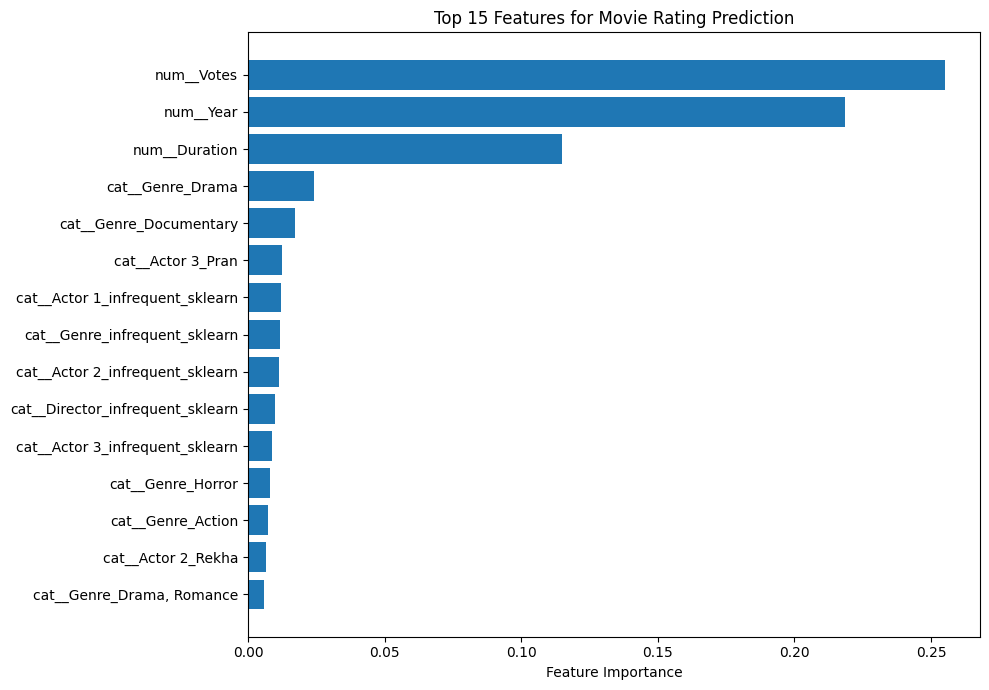

In [ ]:

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

importances = model.named_steps[
    "regressor"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print("Top 15 model features:")
display(importance_df.head(15))

top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Features for Movie Rating Prediction")
plt.tight_layout()
plt.show()


In [ ]:

import joblib
from google.colab import files

# Save the trained model
joblib.dump(model, "movie_rating_model.pkl")

# Save prediction results
results.to_csv("movie_rating_predictions.csv", index=False)

print("Project files saved successfully!")


Project files saved successfully!


In [ ]:

files.download("movie_rating_model.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

files.download("movie_rating_predictions.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

print("=" * 55)
print("CODSOFT DATA SCIENCE INTERNSHIP")
print("TASK 2: MOVIE RATING PREDICTION")
print("=" * 55)

print("\nProject Objective:")
print("Predict IMDb movie ratings using machine learning.")

print("\nDataset:")
print("IMDb Movies India.csv")

print("\nAlgorithm:")
print("Random Forest Regression")

print("\nInput Features:")
print(", ".join(feature_columns))

print("\nEvaluation Results:")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2:   {r2:.4f}")

print("\nConclusion:")
print(
    "The model was trained to estimate movie ratings from "
    "available movie information. Performance was evaluated "
    "using a held-out test dataset."
)

print("\nTask 2 execution completed.")


CODSOFT DATA SCIENCE INTERNSHIP
TASK 2: MOVIE RATING PREDICTION

Project Objective:
Predict IMDb movie ratings using machine learning.

Dataset:
IMDb Movies India.csv

Algorithm:
Random Forest Regression

Input Features:
Year, Duration, Votes, Genre, Director, Actor 1, Actor 2, Actor 3

Evaluation Results:
MAE:  0.8428
RMSE: 1.1195
R2:   0.3259

Conclusion:
The model was trained to estimate movie ratings from available movie information. Performance was evaluated using a held-out test dataset.

Task 2 execution completed.
